## 💡 Important Notes

- This is an **individual, open-book assessment**.
- Submit **one Jupyter notebook** containing your code, outputs, explanations and include your references in refrences.md. Add code and Markdown cells where useful.
- Use only Python libraries used in the lecture notes and exercises. Any version is acceptable.
- Read **Generative AI usage policy** in readme of your repository



# 🌧️ Stormwater Intelligence Report for the Urban Drainage Operations Lab (UDOL)
*(Two Connected ML Tasks — 100 marks total)*

---

## Welcome to UDOL

For this assessment, the Urban Drainage Operations Lab is your client. UDOL supports drainage operators in anticipating high water levels and planning pump inspections.

You have been contracted to develop predictive insights from operating records that combine rainfall, catchment characteristics, drainage measurements and pump-condition information.

UDOL has asked you to complete **two connected analytical tasks**: predict peak water levels and identify pumps at risk of a fault. Both tasks use the same operating cases, allowing you to reuse your data preparation and preprocessing design.

**In summary complete Task 1 and Task 2**

---

### 📦 About the Dataset

The supplied file, **`stormwater_M_enhanced.csv`**, contains **4,005 records and 22 columns** representing simulated operating cases. The intended use is prediction for additional cases under similar conditions.

#### **Rainfall and Catchment Conditions**

- `forecast_rainfall`, `antecedent_rainfall` — forecast rainfall over the next six hours and measured rainfall over the preceding 24 hours, in millimetres.
- `catchment_area_ha`, `catchment_scale_sqrt_ha` — catchment area.
- `impervious_percent` — the percentage of the catchment covered by impervious surfaces.
- `soil_group`, `soil_moisture_percent` — the predominant soil type and a current soil-moisture probe reading.

#### **Drainage and Flow Measurements**

- `drainage_capacity_m3_s`, `blockage_percent` — rated drainage capacity and the most recent estimate of obstruction.
- `current_water_level_m` — water level when the prediction is issued.
- `flow_sensor_A`, `flow_sensor_B` — current inflow estimates from two sensors measuring the same quantity.
- `capacity_utilisation_percent` — sensor-B inflow relative to blockage-adjusted drainage capacity, expressed as a percentage.

#### **Pump Condition and Reporting Information**

- `pump_type`, `pump_age_years` — the pump design and its age.
- `vibration_mm_s`, `maintenance_weeks` — current vibration and time since the last maintenance visit.
- `telemetry_method` — the communication method used to submit measurements.
- `sample_id` — the underlying operating-case identifier.
- `telemetry_packet_id` — the administrative label assigned to an exported record.

#### **Future Outcomes**

- `peak_water_level_m` — the highest water level in the next six hours. **Target for Task 1: regression.**
- `pump_fault_24h` — whether a fault occurs (`1` = fault, `0` = no fault). **Target for Task 2: classification.**

Neither future outcome is available when predictions are issued. **Exclude both outcomes and `sample_id` from the inputs for either model.**

---

Note: The dataset may contain duplicates, missing values, and sentinel values. You are expected to detect and handle these appropriately.

---
split the dataset into 70% for training and 30% for testing. Given the structure of this project, there’s no need for a separate validation set, as UDOL wants you to maximize training data usage through cross-validation.
- `random_state`:  For any operation involving randomness, you must set: random_state = 42
- Whenever/if you use cross-validation: use cv = 5 

In [2]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

# Load the source data. Keep a raw copy so every cleaning decision can be audited.
raw_df = pd.read_csv("data/stormwater_M_enhanced.csv")
df = raw_df.copy()
print(f"Python executable: {sys.executable}")
print(f"Raw data: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Python executable: c:\Users\28640\.conda\envs\dsml25\python.exe
Raw data: 4,005 rows x 22 columns


,sample_id,forecast_rainfall,antecedent_rainfall,catchment_area_ha,impervious_percent,drainage_capacity_m3_s,current_water_level_m,flow_sensor_A,flow_sensor_B,pump_age_years,vibration_mm_s,maintenance_weeks,blockage_percent,pump_type,soil_group,peak_water_level_m,pump_fault_24h,soil_moisture_percent,catchment_scale_sqrt_ha,capacity_utilisation_percent,telemetry_packet_id,telemetry_method
0,S001673,20.387839,12.133161,26.137507,30.383196,0.699055,0.693476,0.393945,0.393817,18.451474,1.649618,12.584773,33.749733,submersible,loam,1.087548,0,29.232,5.112485,85.034562,PKT-002807,radio
1,S000732,8.502653,24.089749,15.616096,56.268406,0.494458,NaN,0.315918,0.317971,22.022481,3.414727,1.301556,7.618366,submersible,clay,1.611597,0,NaN,3.951721,69.610133,PKT-001893,cellular
2,S001813,56.740222,19.534796,12.678384,58.136818,0.407270,0.414502,0.249966,0.249464,21.894432,2.692392,19.529053,20.974599,centrifugal,loam,0.993944,1,31.451,3.560672,77.510181,PKT-001502,cellular
3,S001552,19.317694,30.458575,17.161898,59.340722,0.126278,0.912577,0.390830,0.389608,12.338783,2.324607,NaN,8.108355,submersible,clay,NaN,0,NaN,4.142692,335.756280,PKT-002969,cellular
4,S000732,8.502653,24.089749,15.616096,56.268406,0.494458,NaN,0.315918,0.317971,22.022481,3.414727,1.301556,7.618366,submersible,clay,1.611597,0,NaN,3.951721,69.610133,PKT-001893,cellular


## 🟦 Task 1 — Forecasting Peak Water Levels (Regression)
*(70 marks)*

UDOL wants to estimate the highest water level from information available when a forecast is issued.

### 🔍 1.1 EDA, Cleaning and Feature Selection / Engineering · 28 marks

Perform an evidence-based EDA and develop a justified preparation strategy.

Include a concise and short **predictor decision log in coment format or markdawn** connecting your evidence, proposed treatment or representation, rationale and implementation. Name your final reusable preprocessing pipeline `prep_pipe`. 


---

### 🤖 1.2 Modelling and Comparison · 22 marks

- Train a **baseline regressor**.
- Compare **a regularised linear model, a Decision Tree and a tree ensemble**.
- Default or near-default settings are sufficient; extensive hyperparameter tuning is not required.
- Select your final model as **`best_regressor`** and explain the evidence supporting the choice.

---
### 🧪 1.3 Final Test Evaluation and Recommendations (10 marks)

Evaluate `best_regressor` 


---
### 💬 1.4 Advice to the Operator · 10 marks

Investigate **one** of the following client claims:

**A. Sensor purchase:** “The two flow sensors provide similar information. We should retain whichever has the larger absolute Linear Regression coefficient.”

**B. Forecast reliability:** “The model with the lowest average error will also give the most stable individual predictions when we update its training data.”

State your expectation, design a controlled investigation using training data, and advise UDOL using quantitative evidence. Account for dependencies between original and derived predictors in your comparisons. Explain what the evidence establishes and what it cannot settle.


### 1.1 EDA and preparation

I check duplicates, missing values, invalid measurements and predictor relationships using the training data. The test set is held back for final evaluation.

In [3]:
# Compact quality audit before cleaning
quality_audit = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing_n": raw_df.isna().sum(),
    "missing_%": (100 * raw_df.isna().mean()).round(1),
    "unique_n": raw_df.nunique(dropna=True)
}).sort_values("missing_%", ascending=False)

duplicate_summary = pd.Series({
    "exact duplicate rows": int(raw_df.duplicated().sum()),
    "rows with a repeated sample_id": int(raw_df.sample_id.duplicated(keep=False).sum()),
    "unique sample_id values": int(raw_df.sample_id.nunique()),
    "missing regression targets": int(raw_df.peak_water_level_m.isna().sum()),
    "negative forecast rainfall values": int(raw_df.forecast_rainfall.lt(0).sum()),
    "impervious values outside 0-100%": int((raw_df.impervious_percent.notna() & ~raw_df.impervious_percent.between(0, 100)).sum()),
    "negative flow_sensor_A values": int(raw_df.flow_sensor_A.lt(0).sum()),
})
print("Record and value checks")
display(duplicate_summary.to_frame("count"))
print("Missingness by field")
display(quality_audit)

Record and value checks


,count
exact duplicate rows,5
rows with a repeated sample_id,15
unique sample_id values,3994
missing regression targets,3
negative forecast rainfall values,4
impervious values outside 0-100%,5
negative flow_sensor_A values,120


Missingness by field


,dtype,missing_n,missing_%,unique_n
soil_moisture_percent,float64,3004,75.0,988
maintenance_weeks,float64,107,2.7,3887
antecedent_rainfall,float64,95,2.4,3898
impervious_percent,float64,96,2.4,3896
vibration_mm_s,float64,97,2.4,3888
capacity_utilisation_percent,float64,92,2.3,3902
blockage_percent,float64,89,2.2,3905
soil_group,object,54,1.3,3
current_water_level_m,float64,30,0.7,3960
peak_water_level_m,float64,3,0.1,3987


Repeated `sample_id` records refer to the same case, so I check that their outcomes agree and combine them before splitting. Invalid negative readings and out-of-range imperviousness become missing values. I drop export identifiers and retain valid high water levels.

In [4]:
# Validate repeated operating-case outcomes, repair sentinels, then collapse exports.
case_target_nunique = raw_df.groupby("sample_id")[["peak_water_level_m", "pump_fault_24h"]].nunique(dropna=True)
assert (case_target_nunique <= 1).all().all(), "A repeated sample_id has conflicting outcomes; inspect before aggregation."

clean_source = raw_df.drop(columns=["telemetry_packet_id"]).copy()
clean_source.loc[clean_source["forecast_rainfall"] < 0, "forecast_rainfall"] = np.nan
clean_source.loc[~clean_source["impervious_percent"].between(0, 100), "impervious_percent"] = np.nan
clean_source.loc[clean_source["flow_sensor_A"] < 0, "flow_sensor_A"] = np.nan

numeric_cols = clean_source.select_dtypes(include=np.number).columns.tolist()
category_cols = [c for c in clean_source.columns if c not in numeric_cols and c != "sample_id"]

def first_non_missing(series):
    values = series.dropna()
    return values.iloc[0] if len(values) else np.nan

def most_common(series):
    values = series.dropna()
    if values.empty:
        return np.nan
    modes = values.mode()
    return modes.iloc[0] if len(modes) else values.iloc[0]

aggregation = {col: "median" for col in numeric_cols}
aggregation["peak_water_level_m"] = first_non_missing
aggregation["pump_fault_24h"] = first_non_missing
aggregation.update({col: most_common for col in category_cols})
case_df = clean_source.groupby("sample_id", as_index=False).agg(aggregation)

n_before_cases = len(raw_df)
n_after_cases = len(case_df)
missing_target_cases = int(case_df["peak_water_level_m"].isna().sum())
eligible_df = case_df.dropna(subset=["peak_water_level_m"]).reset_index(drop=True)
print(f"Collapsed {n_before_cases:,} exported rows to {n_after_cases:,} unique operating cases.")
print(f"Removed {missing_target_cases} case(s) with no observed peak-water-level target; {len(eligible_df):,} cases remain.")
print("Repeated-case outcomes were consistent; numeric repeat measurements were combined by median.")

Collapsed 4,005 exported rows to 3,994 unique operating cases.
Removed 2 case(s) with no observed peak-water-level target; 3,992 cases remain.
Repeated-case outcomes were consistent; numeric repeat measurements were combined by median.


#### Training-set EDA

I split the unique eligible cases once. The plots below use training data only; imputers and encoders are fitted inside each model pipeline.

In [5]:
# Shared eligible cases and 70/30 holdout split (also reusable for Task 2)
excluded_columns = ["sample_id", "peak_water_level_m", "pump_fault_24h"]
X_all = eligible_df.drop(columns=excluded_columns)
y_all = eligible_df["peak_water_level_m"]

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42
)
print(f"Training cases: {len(X_train):,} ({len(X_train)/len(X_all):.1%})")
print(f"Test cases: {len(X_test):,} ({len(X_test)/len(X_all):.1%})")
print(f"Training target mean/median: {y_train.mean():.3f} m / {y_train.median():.3f} m")

Training cases: 2,794 (70.0%)
Test cases: 1,198 (30.0%)
Training target mean/median: 1.602 m / 1.516 m


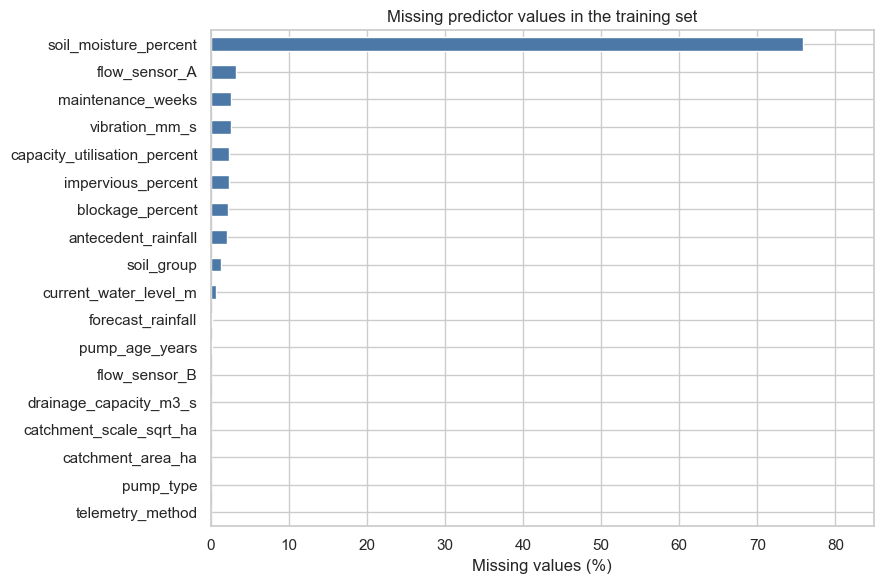

Interpretation: soil_moisture_percent has the most missing training values (75.8%).
Rows are retained; numeric and categorical imputers will be fitted on each training fold only.


In [6]:
# Figure 1 — missingness in the training predictors
missing_pct = (100 * X_train.isna().mean()).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
missing_pct.plot(kind="barh", color="#4C78A8", ax=ax)
ax.set_title("Missing predictor values in the training set")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(5, missing_pct.max() * 1.12))
plt.tight_layout()
plt.show()

most_missing = missing_pct.idxmax()
print(f"Interpretation: {most_missing} has the most missing training values ({missing_pct.max():.1f}%).")
print("Rows are retained; numeric and categorical imputers will be fitted on each training fold only.")

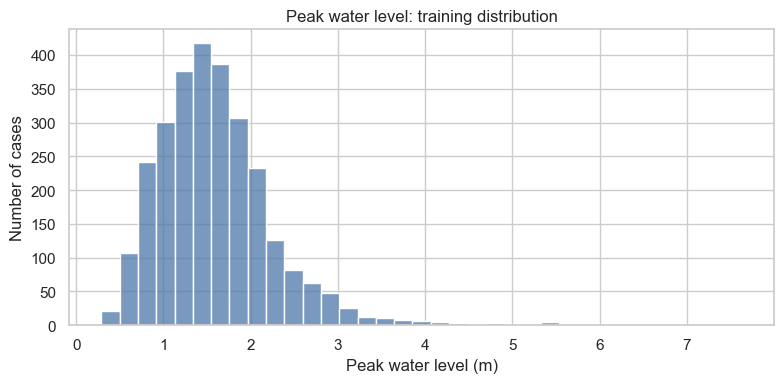

Interpretation: median = 1.52 m; 95th percentile = 2.77 m; 99th percentile = 4.02 m; maximum = 7.63 m.
The upper tail is retained for modelling because these are positive outcomes and no documented target sentinel is present.


In [7]:
# Figure 2 — target distribution and extreme observations in training data
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(y_train, bins=35, color="#4C78A8", ax=ax)
ax.set(title="Peak water level: training distribution", xlabel="Peak water level (m)", ylabel="Number of cases")
plt.tight_layout()
plt.show()

q50, q95, q99 = y_train.quantile([.50, .95, .99])
print(f"Interpretation: median = {q50:.2f} m; 95th percentile = {q95:.2f} m; 99th percentile = {q99:.2f} m; maximum = {y_train.max():.2f} m.")
print("The upper tail is retained for modelling because these are positive outcomes and no documented target sentinel is present.")

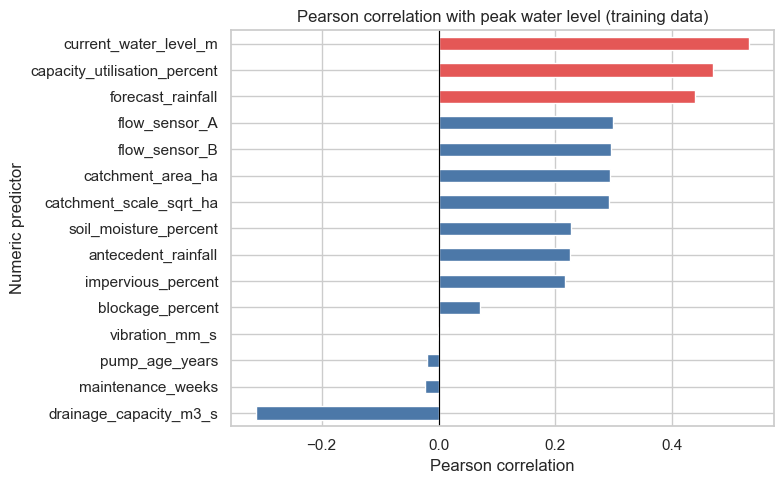

Interpretation: Pearson correlations summarize linear association, not causation; curved relationships and interactions can be missed.
Largest absolute Pearson correlations:


,Pearson correlation
current_water_level_m,0.532
capacity_utilisation_percent,0.469
forecast_rainfall,0.438
drainage_capacity_m3_s,-0.312
flow_sensor_A,0.298


In [8]:
# Figure 3 — Pearson correlations with the target (training partition)
numeric_train = X_train.select_dtypes(include=np.number)
target_corr = numeric_train.assign(peak_water_level_m=y_train).corr(method="pearson")["peak_water_level_m"].drop("peak_water_level_m")
target_corr = target_corr.sort_values(key=lambda values: values.abs(), ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#E45756" if value < 0 else "#4C78A8" for value in target_corr.values]
target_corr.sort_values().plot(kind="barh", color=colors, ax=ax)
ax.axvline(0, color="black", linewidth=.8)
ax.set(title="Pearson correlation with peak water level (training data)", xlabel="Pearson correlation", ylabel="Numeric predictor")
plt.tight_layout()
plt.show()
print("Interpretation: Pearson correlations summarize linear association, not causation; curved relationships and interactions can be missed.")
print("Largest absolute Pearson correlations:")
display(target_corr.head(5).rename("Pearson correlation").to_frame().round(3))

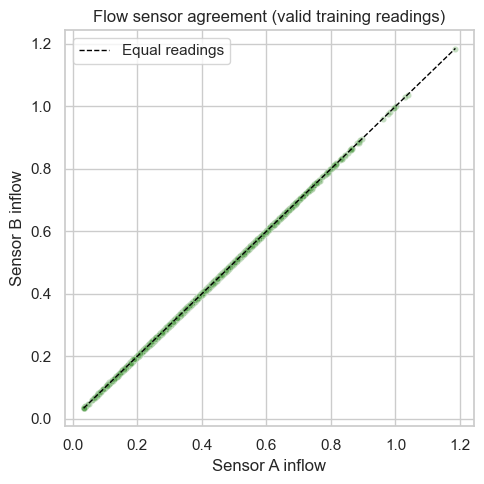

Sensor A/B Pearson correlation: 0.99997 (n=2,702 paired training cases).
The readings are strongly associated, but correlation alone does not show exact agreement or sensor accuracy.


In [9]:
# Figure 4 — compare the two flow sensors for the operator claim
sensor_rows = X_train[["flow_sensor_A", "flow_sensor_B"]].dropna()
fig, ax = plt.subplots(figsize=(5, 5))
sns.scatterplot(data=sensor_rows, x="flow_sensor_A", y="flow_sensor_B", alpha=.35, s=20, ax=ax, color="#59A14F")
lo = min(sensor_rows.min())
hi = max(sensor_rows.max())
ax.plot([lo, hi], [lo, hi], linestyle="--", color="black", linewidth=1, label="Equal readings")
ax.set(title="Flow sensor agreement (valid training readings)", xlabel="Sensor A inflow", ylabel="Sensor B inflow")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Sensor A/B Pearson correlation: {sensor_rows.corr().iloc[0,1]:.5f} (n={len(sensor_rows):,} paired training cases).")
print("The readings are strongly associated, but correlation alone does not show exact agreement or sensor accuracy.")

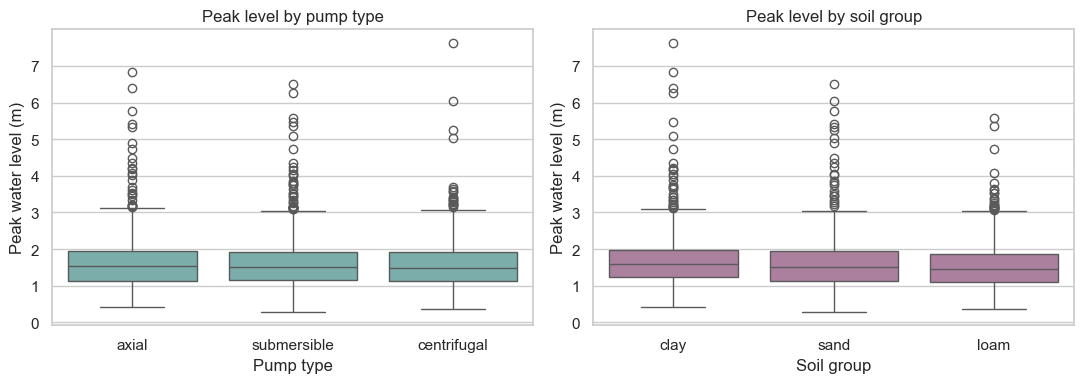

Interpretation: group overlap is substantial, so these categories should be encoded as predictors rather than used as stand-alone decision rules.


In [10]:
# Figure 5 — target distribution across the categorical pump and soil groups
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=pd.DataFrame({"group": X_train["pump_type"], "target": y_train}), x="group", y="target", ax=axes[0], color="#72B7B2")
axes[0].set(title="Peak level by pump type", xlabel="Pump type", ylabel="Peak water level (m)")
sns.boxplot(data=pd.DataFrame({"group": X_train["soil_group"], "target": y_train}), x="group", y="target", ax=axes[1], color="#B279A2")
axes[1].set(title="Peak level by soil group", xlabel="Soil group", ylabel="Peak water level (m)")
plt.tight_layout()
plt.show()
print("Interpretation: group overlap is substantial, so these categories should be encoded as predictors rather than used as stand-alone decision rules.")

#### Predictor decisions

| Evidence | Decision | Reason |
|---|---|---|
| Repeated `sample_id`; outcomes agree. | Combine each case; exclude its ID. | Prevents duplicate cases crossing the split. |
| Negative rainfall/sensor A and imperviousness outside 0–100%. | Treat as missing. | Invalid values should not be modelled as measurements. |
| Missing predictors, especially soil moisture. | Median/mode imputation; add numeric missing indicators. | Retains cases and lets the pipeline learn from training folds. |
| `catchment_scale_sqrt_ha` duplicates area information; utilisation depends on sensor B, capacity and blockage. | Drop the duplicate area feature; retain utilisation and assess the B family together. | Avoids redundant input while accounting for derived-feature dependence. |
| Export IDs and telemetry method describe reporting, not drainage conditions. | Exclude them. | They are not useful operational predictors. |

`prep_pipe` median-imputes and scales numeric features, and mode-imputes and one-hot encodes categories.

In [11]:
# Select predictors after the evidence-based exclusions above.
# Keep raw sensor B and its derived utilisation feature in the main model, but treat
# them as one dependent feature family in the later controlled sensor comparison.
model_drop = ["catchment_scale_sqrt_ha", "telemetry_method"]
X_train_model = X_train.drop(columns=model_drop)
X_test_model = X_test.drop(columns=model_drop)

numeric_features = X_train_model.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train_model.select_dtypes(exclude=np.number).columns.tolist()

def make_preprocessor(feature_columns):
    numeric = [c for c in feature_columns if c in numeric_features]
    categorical = [c for c in feature_columns if c in categorical_features]
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, numeric),
        ("cat", categorical_pipe, categorical)
    ], remainder="drop")

prep_pipe = make_preprocessor(X_train_model.columns.tolist())
print(f"Reusable preprocessing pipeline: {len(numeric_features)} numeric + {len(categorical_features)} categorical predictors.")
print("Model inputs exclude both outcomes, sample_id, telemetry_packet_id, catchment_scale_sqrt_ha, and telemetry_method.")

Reusable preprocessing pipeline: 14 numeric + 2 categorical predictors.
Model inputs exclude both outcomes, sample_id, telemetry_packet_id, catchment_scale_sqrt_ha, and telemetry_method.


### 1.2 Model comparison

I compare a mean baseline, Ridge, a decision tree and a random forest using the same five training folds. The test set remains untouched until selection.

In [12]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
model_specs = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Ridge regression": Ridge(alpha=1.0),
    "Decision tree": DecisionTreeRegressor(random_state=42),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=1)
}

cv_rows = []
model_pipelines = {}
for name, estimator in model_specs.items():
    pipe = Pipeline([("prep", clone(prep_pipe)), ("model", estimator)])
    scores = cross_validate(
        pipe, X_train_model, y_train, cv=cv5,
        scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"},
        n_jobs=1, return_train_score=False
    )
    model_pipelines[name] = pipe
    cv_rows.append({
        "Model": name,
        "CV MAE (m)": -scores["test_mae"].mean(),
        "CV MAE SD (m)": scores["test_mae"].std(),
        "CV RMSE (m)": -scores["test_rmse"].mean(),
        "CV R²": scores["test_r2"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV MAE (m)").reset_index(drop=True)
display(cv_results.round(3))
best_name = cv_results.loc[0, "Model"]
best_regressor = model_pipelines[best_name]
best_regressor.fit(X_train_model, y_train)
print(f"Selected best_regressor: {best_name}, based on the lowest mean five-fold MAE.")
print("MAE is the primary selection metric because it reports a typical absolute water-level error in metres; RMSE is also shown to expose sensitivity to large misses.")

,Model,CV MAE (m),CV MAE SD (m),CV RMSE (m),CV R²
0,Random forest,0.183,0.007,0.283,0.834
1,Ridge regression,0.207,0.006,0.326,0.781
2,Decision tree,0.283,0.013,0.445,0.590
3,Mean baseline,0.499,0.017,0.697,-0.003


Selected best_regressor: Random forest, based on the lowest mean five-fold MAE.
MAE is the primary selection metric because it reports a typical absolute water-level error in metres; RMSE is also shown to expose sensitivity to large misses.


### 1.3 Test evaluation

I evaluate the selected model once on the held-out test set. MAE and RMSE are in metres; R² summarizes explained variation.

Holdout cases: 1,198
MAE:  0.168 m
RMSE: 0.236 m
R²:   0.865


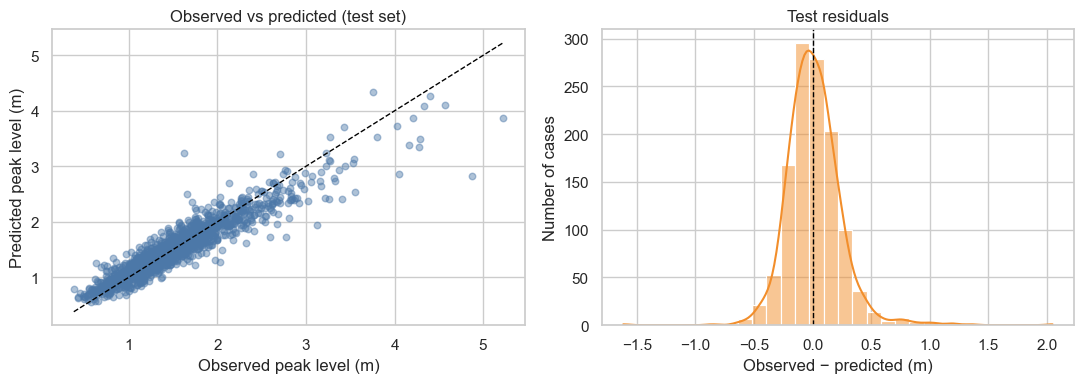

Test residual median: -0.006 m; 90th percentile absolute error: 0.332 m.


In [13]:
# Figure 6 — final test diagnostics
test_prediction = best_regressor.predict(X_test_model)
test_mae = mean_absolute_error(y_test, test_prediction)
test_rmse = np.sqrt(mean_squared_error(y_test, test_prediction))
test_r2 = r2_score(y_test, test_prediction)
print(f"Holdout cases: {len(y_test):,}")
print(f"MAE:  {test_mae:.3f} m")
print(f"RMSE: {test_rmse:.3f} m")
print(f"R²:   {test_r2:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, test_prediction, alpha=.45, s=22, color="#4C78A8")
lo = min(y_test.min(), test_prediction.min())
hi = max(y_test.max(), test_prediction.max())
axes[0].plot([lo, hi], [lo, hi], "--", color="black", linewidth=1)
axes[0].set(title="Observed vs predicted (test set)", xlabel="Observed peak level (m)", ylabel="Predicted peak level (m)")
residuals = y_test - test_prediction
sns.histplot(residuals, bins=30, kde=True, color="#F28E2B", ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(title="Test residuals", xlabel="Observed − predicted (m)", ylabel="Number of cases")
plt.tight_layout()
plt.show()
print(f"Test residual median: {residuals.median():.3f} m; 90th percentile absolute error: {residuals.abs().quantile(.90):.3f} m.")

### 1.4 Sensor advice

I test the claim that the sensor with the larger absolute linear coefficient should be retained. Since A and B are highly related and utilisation is derived from B, I compare standardized coefficients and cross-validated errors for controlled feature groups, keeping B with its derived feature.

In [14]:
# Standardised full-model coefficients are descriptive only under collinearity.
coefficient_model = Pipeline([
    ("prep", clone(prep_pipe)),
    ("model", LinearRegression())
])
coefficient_model.fit(X_train_model, y_train)
feature_names = coefficient_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(coefficient_model.named_steps["model"].coef_, index=feature_names)
sensor_coef_rows = []
for feature in ["flow_sensor_A", "flow_sensor_B", "capacity_utilisation_percent"]:
    matching = coefs[coefs.index.str.endswith("__" + feature)]
    sensor_coef_rows.append({
        "Feature": feature,
        "Standardised coefficient": matching.iloc[0] if len(matching) else np.nan,
        "Absolute coefficient": abs(matching.iloc[0]) if len(matching) else np.nan
    })
sensor_coefficients = pd.DataFrame(sensor_coef_rows).set_index("Feature")
print("Standardised coefficients from a full linear model (one standard deviation change in a numeric input):")
display(sensor_coefficients.round(3))
print("These values are conditional on the other correlated predictors and are not standalone sensor-value scores.")

Standardised coefficients from a full linear model (one standard deviation change in a numeric input):


,Standardised coefficient,Absolute coefficient
Feature,,
flow_sensor_A,0.009,0.009
flow_sensor_B,-0.090,0.090
capacity_utilisation_percent,0.249,0.249


These values are conditional on the other correlated predictors and are not standalone sensor-value scores.


In [15]:
# Controlled group ablation with identical five-fold splits and Ridge regression.
# B is assessed together with its derived utilisation ratio; A remains separate.
sensor_feature_groups = {
    "All sensor predictors (A + B + utilisation)": list(X_train_model.columns),
    "Both raw sensors (A + B)": [c for c in X_train_model.columns if c != "capacity_utilisation_percent"],
    "Sensor A only": [c for c in X_train_model.columns if c not in ["flow_sensor_B", "capacity_utilisation_percent"]],
    "Sensor B + derived utilisation": [c for c in X_train_model.columns if c != "flow_sensor_A"],
    "Neither sensor family": [c for c in X_train_model.columns if c not in ["flow_sensor_A", "flow_sensor_B", "capacity_utilisation_percent"]]
}

sensor_rows = []
for label, features in sensor_feature_groups.items():
    prep = make_preprocessor(features)
    pipe = Pipeline([("prep", prep), ("model", Ridge(alpha=1.0))])
    scores = cross_validate(
        pipe, X_train_model[features], y_train, cv=cv5,
        scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"},
        n_jobs=1, return_train_score=False
    )
    sensor_rows.append({
        "Feature group": label,
        "CV MAE (m)": -scores["test_mae"].mean(),
        "CV MAE SD (m)": scores["test_mae"].std(),
        "CV RMSE (m)": -scores["test_rmse"].mean()
    })
sensor_results = pd.DataFrame(sensor_rows).sort_values("CV MAE (m)").reset_index(drop=True)
display(sensor_results.round(3))

mae_by_group = sensor_results.set_index("Feature group")["CV MAE (m)"]
best_sensor_group = mae_by_group.idxmin()
print(f"Lowest mean CV MAE was for: {best_sensor_group} ({mae_by_group.min():.3f} m).")
mae_a_only = mae_by_group["Sensor A only"]
mae_b_group = mae_by_group["Sensor B + derived utilisation"]
mae_all_sensors = mae_by_group["All sensor predictors (A + B + utilisation)"]
print(f"The B + utilisation group improves on A alone by {mae_a_only - mae_b_group:.3f} m CV MAE.")
print(f"Incremental CV MAE improvement from adding A to the B + utilisation group: {mae_b_group - mae_all_sensors:.4f} m (positive means lower error).")
print("The B-derived feature group has slightly lower CV MAE than A alone; adding A to the B group changes error little. This predictive comparison does not establish sensor accuracy or procurement value.")

,Feature group,CV MAE (m),CV MAE SD (m),CV RMSE (m)
0,Sensor B + derived utilisation,0.207,0.006,0.325
1,All sensor predictors (A + B + utilisation),0.207,0.006,0.326
2,Sensor A only,0.220,0.009,0.346
3,Both raw sensors (A + B),0.220,0.009,0.346
4,Neither sensor family,0.222,0.009,0.348


Lowest mean CV MAE was for: Sensor B + derived utilisation (0.207 m).
The B + utilisation group improves on A alone by 0.013 m CV MAE.
Incremental CV MAE improvement from adding A to the B + utilisation group: -0.0003 m (positive means lower error).
The B-derived feature group has slightly lower CV MAE than A alone; adding A to the B group changes error little. This predictive comparison does not establish sensor accuracy or procurement value.


### Task 1 summary

The random forest had the lowest five-fold training MAE (0.183 m). On the held-out test set, MAE was 0.168 m, RMSE 0.236 m and R² 0.865. These results describe similar simulated cases; they do not establish performance on real systems or rare extremes.

---

## 🟧 Task 2 — Identifying Pump Faults (Classification)
*(30 marks)*

UDOL also wants to identify pumps that may develop a fault, so that inspection decisions can reflect the risk of missing a fault.

### 🔧 2.1 Reuse and Compare · 5 marks

There is **no need to repeat EDA**. Reuse your preprocessing design and the shared eligible cases and split from Task 1, making adjustments only where justified for classification and **not need to justify these steps (preprocessing) in detail**..

### 2.2 Modelling and Comparison . 10 marks

- Train a **baseline classifier** and compare **Random Forest and KNN**.
- Select your final classifier as **`best_classifier`**.

### 2.3 Pump Inspection Decisions · 15 marks

Evaluate `best_classifier` using its **standard decision rule**. Report **ROC-AUC, accuracy, precision, recall, F1 and a confusion matrix**.

A missed fault costs UDOL **five times as much as an unnecessary inspection**. For this comparison, count only these error costs. Interpret the observed errors and advise whether the standard decision rule is suitable for the operator's priorities. Further threshold optimisation is not required.



### 2.1 Reuse data and preprocessing

I reuse Task1's eligible cases, split and `prep_pipe`. A stratified five-fold split keeps fault proportions similar across folds; preprocessing is fitted within each fold.

In [16]:
# Reuse the exact Task 1 case split and preprocessing design.
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold

y_fault_train = eligible_df.loc[X_train.index, 'pump_fault_24h'].astype(int)
y_fault_test = eligible_df.loc[X_test.index, 'pump_fault_24h'].astype(int)
assert X_train.index.equals(y_fault_train.index)
assert X_test.index.equals(y_fault_test.index)

fault_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### 2.2 Model comparison

I compare the majority-class baseline, random forest and KNN. I select by cross-validated cost (`5 × missed faults + unnecessary inspections`), using ROC-AUC to break ties.

In [17]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '1'  # all TASK2 estimators use one worker

fault_models = {
    'Most-frequent baseline': DummyClassifier(strategy='most_frequent'),
    'Random forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1),
    'KNN (5 neighbours)': KNeighborsClassifier(n_neighbors=5, n_jobs=1, algorithm='kd_tree'),
}

fault_cv_rows = []
fault_pipelines = {}
for name, estimator in fault_models.items():
    pipe = Pipeline([('prep', clone(prep_pipe)), ('model', estimator)])
    oof_pred = np.empty(len(y_fault_train), dtype=int)
    fold_scores = []
    for fit_idx, val_idx in fault_cv.split(X_train_model, y_fault_train):
        fold_pipe = clone(pipe)
        fold_pipe.fit(X_train_model.iloc[fit_idx], y_fault_train.iloc[fit_idx])
        y_val = y_fault_train.iloc[val_idx]
        pred = fold_pipe.predict(X_train_model.iloc[val_idx])
        prob = fold_pipe.predict_proba(X_train_model.iloc[val_idx])[:, 1]
        oof_pred[val_idx] = pred
        fold_scores.append({
            'ROC-AUC': roc_auc_score(y_val, prob),
            'Accuracy': accuracy_score(y_val, pred),
            'Precision': precision_score(y_val, pred, zero_division=0),
            'Recall': recall_score(y_val, pred, zero_division=0),
            'F1': f1_score(y_val, pred, zero_division=0),
        })
    _, fp, fn, _ = confusion_matrix(y_fault_train, oof_pred, labels=[0, 1]).ravel()
    cost = 5 * fn + fp
    mean_scores = pd.DataFrame(fold_scores).mean()
    fault_pipelines[name] = pipe
    fault_cv_rows.append({
        'Model': name,
        **{f'CV {metric}': mean_scores[metric] for metric in ['ROC-AUC', 'Accuracy', 'Precision', 'Recall', 'F1']},
        'CV missed faults': int(fn),
        'CV unnecessary inspections': int(fp),
        'CV cost (5×FN + FP)': int(cost),
        'CV cost per case': cost / len(y_fault_train),
    })

fault_cv_results = pd.DataFrame(fault_cv_rows).sort_values(
    ['CV cost per case', 'CV ROC-AUC'], ascending=[True, False]
).reset_index(drop=True)
display(fault_cv_results.round(3))

best_classifier_name = fault_cv_results.loc[0, 'Model']
best_classifier = fault_pipelines[best_classifier_name]
best_classifier.fit(X_train_model, y_fault_train)
print(f'Selected best_classifier: {best_classifier_name}')
print('Selection is based on the lowest out-of-fold training error cost (5 per missed fault, 1 per unnecessary inspection); ROC-AUC breaks a cost tie.')

,Model,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1,CV missed faults,CV unnecessary inspections,CV cost (5×FN + FP),CV cost per case
0,Random forest,0.743,0.802,0.776,0.240,0.366,506,46,2576,0.922
1,KNN (5 neighbours),0.652,0.773,0.560,0.242,0.337,505,129,2654,0.950
2,Most-frequent baseline,0.500,0.762,0.000,0.000,0.000,666,0,3330,1.192


Selected best_classifier: Random forest
Selection is based on the lowest out-of-fold training error cost (5 per missed fault, 1 per unnecessary inspection); ROC-AUC breaks a cost tie.


### 2.3 Test decisions

I evaluate the selected classifier once on the held-out cases using its default decision rule, then report the requested metrics, confusion matrix and error cost.

In [18]:
# One final evaluation on the untouched test set using the classifier's standard 0.5 threshold.
test_fault_pred = best_classifier.predict(X_test_model)
test_fault_prob = best_classifier.predict_proba(X_test_model)[:, 1]
test_cm = confusion_matrix(y_fault_test, test_fault_pred, labels=[0, 1])
tn, fp, fn, tp = test_cm.ravel()
test_cost = 5 * fn + fp

test_metrics = pd.Series({
    'ROC-AUC': roc_auc_score(y_fault_test, test_fault_prob),
    'Accuracy': accuracy_score(y_fault_test, test_fault_pred),
    'Precision': precision_score(y_fault_test, test_fault_pred, zero_division=0),
    'Recall': recall_score(y_fault_test, test_fault_pred, zero_division=0),
    'F1': f1_score(y_fault_test, test_fault_pred, zero_division=0),
    'Missed-fault cost (5×FN)': 5 * fn,
    'Unnecessary-inspection cost (FP)': fp,
    'Total error cost (5×FN + FP)': test_cost,
    'Error cost per test case': test_cost / len(y_fault_test),
})
print(f'Final classifier: {best_classifier_name}; test cases: {len(y_fault_test):,}; fault cases: {int(y_fault_test.sum()):,}')
display(test_metrics.to_frame('Value').round(3))
print('Confusion matrix (rows = actual [no fault, fault]; columns = predicted [no fault, fault]):')
display(pd.DataFrame(test_cm, index=['Actual no fault', 'Actual fault'], columns=['Predicted no fault', 'Predicted fault']))

miss_rate = fn / (fn + tp) if (fn + tp) else np.nan
inspection_rate = (fp + tp) / len(y_fault_test)
print(f'The standard rule misses {fn} of {fn + tp} observed faults ({miss_rate:.1%}) and flags {inspection_rate:.1%} of test cases for inspection.')
print(f'Observed test error cost = 5×{fn} missed faults + {fp} unnecessary inspections = {test_cost}.')
if fn > 0:
    print('Recommendation: the standard 0.5 rule is not suitable for UDOL’s stated priorities here: it misses most observed faults, and each miss costs five times an unnecessary inspection. Threshold optimisation was not requested, so this evaluation does not choose an alternative threshold.')
else:
    print('No test faults were missed in this holdout, but this finite result does not establish that future misses will be absent. The default threshold still does not encode the stated cost asymmetry; validate on additional cases before relying on it.')

Final classifier: Random forest; test cases: 1,198; fault cases: 294


,Value
ROC-AUC,0.741
Accuracy,0.787
Precision,0.697
Recall,0.235
F1,0.351
Missed-fault cost (5×FN),1125.000
Unnecessary-inspection cost (FP),30.000
Total error cost (5×FN + FP),1155.000
Error cost per test case,0.964


Confusion matrix (rows = actual [no fault, fault]; columns = predicted [no fault, fault]):


,Predicted no fault,Predicted fault
Actual no fault,874,30
Actual fault,225,69


The standard rule misses 225 of 294 observed faults (76.5%) and flags 8.3% of test cases for inspection.
Observed test error cost = 5×225 missed faults + 30 unnecessary inspections = 1155.
Recommendation: the standard 0.5 rule is not suitable for UDOL’s stated priorities here: it misses most observed faults, and each miss costs five times an unnecessary inspection. Threshold optimisation was not requested, so this evaluation does not choose an alternative threshold.


### Task 2 summary

The random forest had the lowest cross-validated error cost and was selected as `best_classifier`. On the held-out test set, it achieved ROC-AUC 0.741, accuracy 0.787, precision 0.697, recall 0.235 and F1 0.351. It missed 225 of 294 faults, giving a total error cost of 1,155. The default decision rule is therefore unsuitable when missed faults cost five times as much as unnecessary inspections. Results are based on simulated cases and may differ under real operating conditions.


---

## 📘 Deliverables

Submit **one completed Jupyter notebook**:

- Use concise Markdown explanations to show what you decided and why.
- Include the outputs and comparisons supporting those decisions.
- Summarise your final recommendations and limitations in a short concluding paragraph.
- Include your references and acknowledgements under the current course rules in refrence.md 
- Restart the kernel and run the completed notebook in order before submission.
